# MLT Homework Assignment #3. Optimization algorithms

Nedorezov Danil

**Assignment:**
1. Apply a Logistic Regression model using the functions from the notebook
   *Logistic Regression as a Neural Network - BP alg.ipynb* to predict the biological response of a molecule.
   Use 75% of the dataset to train the model and the rest to estimate its accuracy.
2. Modify the `optimize()` function to implement the stochastic gradient descent (SGD) method and apply it to
   the problem from p. 1.
3. Implement the Adam optimization method using the numpy library and compare the accuracy of the model
   fitted with it with the models trained by the classic GD (p. 1) and SGD (p. 2).
4. For the three modifications of gradient descent plot the learning curves (the value of the loss function
   against the iteration number).
5. Train the models with at least 5 different values of the learning rate, plot the learning curves for all
   these cases and describe how it affects the accuracy of the model.
6. Write conclusions.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

SEED = 1
plt.rcParams["figure.figsize"] = (7, 5)
%matplotlib inline

## 1. Data and the logistic regression from notebook

In [2]:
bioresponse = pd.read_csv("data/bioresponse.csv")
print(bioresponse.shape)
bioresponse.iloc[:, :6].head()

(3751, 1777)


,Activity,D1,D2,D3,D4,D5
0,1,0.000000,0.497009,0.10,0.0,0.132956
1,1,0.366667,0.606291,0.05,0.0,0.111209
2,1,0.033300,0.480124,0.00,0.0,0.209791
3,1,0.000000,0.538825,0.00,0.5,0.196344
4,0,0.100000,0.517794,0.00,0.0,0.494734


In [3]:
X_all = bioresponse.drop(columns="Activity").values
y_all = bioresponse["Activity"].values

print("descriptor matrix: min = {:.1f}, max = {:.1f}".format(X_all.min(), X_all.max()))
print("class balance:", np.bincount(y_all), "-> {:.1%} of class 1".format(y_all.mean()))

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, stratify=y_all, random_state=SEED
)

X_train, X_test = X_train.T, X_test.T
Y_train, Y_test = y_train.reshape(1, -1), y_test.reshape(1, -1)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Y_train:", Y_train.shape, " Y_test:", Y_test.shape)

descriptor matrix: min = 0.0, max = 1.0
class balance: [1717 2034] -> 54.2% of class 1
X_train: (1776, 2813)  X_test: (1776, 938)
Y_train: (1, 2813)  Y_test: (1, 938)


In [ ]:
def sigmoid(z):
    return 1. / (1. + np.exp(-z))


def initialize_with_zeros(dim):
    w = np.random.normal(loc=0.0, scale=1.0, size=dim).reshape(dim, 1)
    b = 0.
    return w, b


def propagate(w, b, X, Y):
    m = X.shape[1]

    A = sigmoid(np.dot(w.T, X) + b)
    A = np.clip(A, 1e-12, 1 - 1e-12)
    cost = float(-(1. / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A)))

    dw = (1. / m) * np.dot(X, (A - Y).T)
    db = (1. / m) * np.sum(A - Y)

    grads = {"dw": dw, "db": db}
    return grads, cost


def predict(w, b, X, threshold=0.5):
    m = X.shape[1]
    Y_prediction = np.zeros((1, m))
    w = w.reshape(X.shape[0], 1)

    A = sigmoid(np.dot(w.T, X) + b)
    for i in range(A.shape[1]):
        if A[0, i] <= threshold:
            Y_prediction[0][i] = 0
        else:
            Y_prediction[0][i] = 1

    return Y_prediction

### 1.3. The classic gradient descent (p. 1)

In [5]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False, record_every=25):
    costs = []

    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        # update rule
        w -= learning_rate * dw
        b -= learning_rate * db

        if i % record_every == 0:
            costs.append(cost)
        if print_cost and i % 500 == 0:
            print(f"Cost after iteration {i}: {cost:.6f}")

    params = {"w": w, "b": b}
    grads = {"dw": dw, "db": db}
    return params, grads, costs

In [6]:
def model(optimizer, X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.1, **kwargs):
    np.random.seed(SEED)
    w, b = initialize_with_zeros(X_train.shape[0])

    start = time.time()
    params, grads, costs = optimizer(w, b, X_train, Y_train, num_iterations, learning_rate, **kwargs)
    elapsed = time.time() - start

    w, b = params["w"], params["b"]
    Y_prediction_train = predict(w, b, X_train)
    Y_prediction_test = predict(w, b, X_test)

    return {
        "costs": costs,
        "train_accuracy": float(np.mean(Y_prediction_train == Y_train)),
        "test_accuracy": float(np.mean(Y_prediction_test == Y_test)),
        "final_cost": costs[-1],
        "time": elapsed,
        "w": w, "b": b,
        "learning_rate": learning_rate,
        "num_iterations": num_iterations,
    }

In [7]:
NUM_ITERATIONS = 2000
LEARNING_RATE = 0.1

gd_result = model(optimize, X_train, Y_train, X_test, Y_test,
                  num_iterations=NUM_ITERATIONS, learning_rate=LEARNING_RATE, print_cost=True)

print()
print(f"train accuracy: {gd_result['train_accuracy']:.4f}")
print(f"test accuracy : {gd_result['test_accuracy']:.4f}")
print(f"training time : {gd_result['time']:.2f} s")

Cost after iteration 0: 4.276616


Cost after iteration 500: 1.103632


Cost after iteration 1000: 0.805297


Cost after iteration 1500: 0.661731



train accuracy: 0.7792
test accuracy : 0.7271
training time : 3.88 s


## 2. Stochastic gradient descent (p. 2)

In [8]:
def optimize_sgd(w, b, X, Y, num_iterations, learning_rate, batch_size=32,
                 print_cost=False, record_every=25, seed=SEED):
    costs = []
    rng = np.random.default_rng(seed)
    m = X.shape[1]

    for i in range(num_iterations):
        # the only difference from optimize(): the gradient is estimated on a random mini-batch
        idx = rng.integers(0, m, batch_size)
        grads, _ = propagate(w, b, X[:, idx], Y[:, idx])
        dw, db = grads["dw"], grads["db"]

        w -= learning_rate * dw
        b -= learning_rate * db

        if i % record_every == 0:
            costs.append(propagate(w, b, X, Y)[1])
        if print_cost and i % 500 == 0:
            print(f"Cost after iteration {i}: {costs[-1]:.6f}")

    params = {"w": w, "b": b}
    grads = {"dw": dw, "db": db}
    return params, grads, costs

In [9]:
sgd_result = model(optimize_sgd, X_train, Y_train, X_test, Y_test,
                   num_iterations=NUM_ITERATIONS, learning_rate=LEARNING_RATE,
                   batch_size=32, print_cost=True)

print()
print(f"train accuracy: {sgd_result['train_accuracy']:.4f}")
print(f"test accuracy : {sgd_result['test_accuracy']:.4f}")
print(f"training time : {sgd_result['time']:.2f} s")
print(f"objects processed: {NUM_ITERATIONS * 32} vs {NUM_ITERATIONS * X_train.shape[1]} for GD")

Cost after iteration 0: 4.153883
Cost after iteration 500: 1.149898
Cost after iteration 1000: 0.831418


Cost after iteration 1500: 0.696470



train accuracy: 0.7732
test accuracy : 0.7228
training time : 0.26 s
objects processed: 64000 vs 5626000 for GD


## 3. Adam (p. 3)

In [ ]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8,
                  print_cost=False, record_every=25):
    costs = []

    v_w, s_w = np.zeros_like(w), np.zeros_like(w)
    v_b, s_b = 0., 0.

    for i in range(1, num_iterations + 1):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        v_w = beta1 * v_w + (1 - beta1) * dw
        v_b = beta1 * v_b + (1 - beta1) * db
        s_w = beta2 * s_w + (1 - beta2) * dw ** 2
        s_b = beta2 * s_b + (1 - beta2) * db ** 2

        v_w_corr, v_b_corr = v_w / (1 - beta1 ** i), v_b / (1 - beta1 ** i)
        s_w_corr, s_b_corr = s_w / (1 - beta2 ** i), s_b / (1 - beta2 ** i)

        w -= learning_rate * v_w_corr / (np.sqrt(s_w_corr) + epsilon)
        b -= learning_rate * v_b_corr / (np.sqrt(s_b_corr) + epsilon)

        if (i - 1) % record_every == 0:
            costs.append(cost)
        if print_cost and (i - 1) % 500 == 0:
            print(f"Cost after iteration {i - 1}: {cost:.6f}")

    params = {"w": w, "b": b}
    grads = {"dw": dw, "db": db}
    return params, grads, costs

In [11]:
adam_result = model(optimize_adam, X_train, Y_train, X_test, Y_test,
                    num_iterations=NUM_ITERATIONS, learning_rate=LEARNING_RATE, print_cost=True)

print()
print(f"train accuracy: {adam_result['train_accuracy']:.4f}")
print(f"test accuracy : {adam_result['test_accuracy']:.4f}")
print(f"training time : {adam_result['time']:.2f} s")

Cost after iteration 0: 4.276616


Cost after iteration 500: 0.169207


Cost after iteration 1000: 0.133994


Cost after iteration 1500: 0.115168



train accuracy: 0.9669
test accuracy : 0.7249
training time : 3.89 s


### Comparison of the three optimizers

All three are run for the same number of iterations, from the same initialization and with the same learning
rate, so the only thing that differs is the update rul


In [12]:
results = {"GD": gd_result, "SGD (batch=32)": sgd_result, "Adam": adam_result}

comparison = pd.DataFrame({
    name: {
        "final train cost": r["final_cost"],
        "train accuracy": r["train_accuracy"],
        "test accuracy": r["test_accuracy"],
        "time, s": r["time"],
    } for name, r in results.items()
}).T
comparison.round(4)

,final train cost,train accuracy,test accuracy,"time, s"
GD,0.5799,0.7792,0.7271,3.8794
SGD (batch=32),0.6015,0.7732,0.7228,0.2612
Adam,0.1018,0.9669,0.7249,3.8874


## 4. Learning curves of the three methods (p. 4)

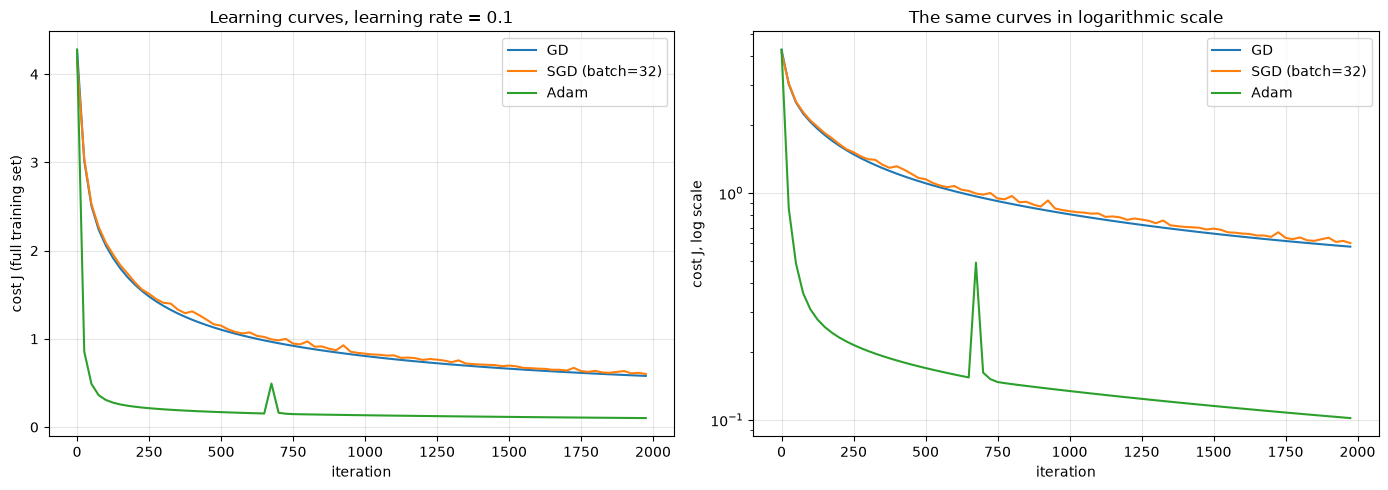

In [13]:
iters = np.arange(0, NUM_ITERATIONS, 25)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, r in results.items():
    ax[0].plot(iters, r["costs"], label=name)
    ax[1].plot(iters, r["costs"], label=name)

ax[0].set_xlabel("iteration")
ax[0].set_ylabel("cost J (full training set)")
ax[0].set_title(f"Learning curves, learning rate = {LEARNING_RATE}")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].set_yscale("log")
ax[1].set_xlabel("iteration")
ax[1].set_ylabel("cost J, log scale")
ax[1].set_title("The same curves in logarithmic scale")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**What the curves show.**

- **GD** decreases smoothly and monotonically — it always follows the exact gradient of the full training
  set — but slowly: every iteration makes only one small step.
- **SGD** follows a similar trajectory while touching a tiny fraction of the data per iteration, which makes
  it dramatically cheaper in wall-clock time. Its curve is visibly noisy: the mini-batch gradient is only an
  estimate of the true one, so individual steps may increase the cost even though the trend goes down.
- **Adam** drops much faster than both from the very first iterations and reaches a far lower cost. Dividing
  by $\sqrt{\hat{s}}$ equalizes the scale of the updates across the 1776 descriptors, many of which are
  binary and rarely active, so the rare but informative features are no longer updated hundreds of times
  slower than the dense ones.

## 5. The effect of the learning rate (p. 5)

In [14]:
LEARNING_RATES = [0.0001, 0.001, 0.01, 0.1, 1.0]
OPTIMIZERS = {
    "GD": (optimize, {}),
    "SGD (batch=32)": (optimize_sgd, {"batch_size": 32}),
    "Adam": (optimize_adam, {}),
}

lr_results = {}
rows = []
for name, (opt, kwargs) in OPTIMIZERS.items():
    for lr in LEARNING_RATES:
        r = model(opt, X_train, Y_train, X_test, Y_test,
                  num_iterations=NUM_ITERATIONS, learning_rate=lr, **kwargs)
        lr_results[(name, lr)] = r
        rows.append({"optimizer": name, "learning_rate": lr,
                     "final train cost": r["final_cost"],
                     "train accuracy": r["train_accuracy"],
                     "test accuracy": r["test_accuracy"]})

lr_table = pd.DataFrame(rows)
lr_table.round(4)

,optimizer,learning_rate,final train cost,train accuracy,test accuracy
0,GD,0.0001,4.0412,0.4856,0.5011
1,GD,0.0010,3.1846,0.5073,0.5405
2,GD,0.0100,1.6250,0.6132,0.6183
3,GD,0.1000,0.5799,0.7792,0.7271
4,GD,1.0000,0.5459,0.7451,0.6940
5,SGD (batch=32),0.0001,4.0390,0.4852,0.5011
6,SGD (batch=32),0.0010,3.1874,0.5084,0.5405
7,SGD (batch=32),0.0100,1.6300,0.6097,0.6247
8,SGD (batch=32),0.1000,0.6015,0.7732,0.7228
9,SGD (batch=32),1.0000,0.7046,0.8091,0.7409


In [15]:
pivot_test = lr_table.pivot(index="learning_rate", columns="optimizer", values="test accuracy")
pivot_cost = lr_table.pivot(index="learning_rate", columns="optimizer", values="final train cost")
print("test accuracy:")
print(pivot_test.round(4).to_string())
print("\nfinal train cost:")
print(pivot_cost.round(4).to_string())

for name in OPTIMIZERS:
    sub = lr_table[lr_table["optimizer"] == name]
    best = sub.loc[sub["test accuracy"].idxmax()]
    print(f"\n{name}: best test accuracy {best['test accuracy']:.4f} at learning rate {best['learning_rate']}")

test accuracy:
optimizer        Adam      GD  SGD (batch=32)
learning_rate                                
0.0001         0.5597  0.5011          0.5011
0.0010         0.7303  0.5405          0.5405
0.0100         0.7239  0.6183          0.6247
0.1000         0.7249  0.7271          0.7228
1.0000         0.7303  0.6940          0.7409

final train cost:
optimizer        Adam      GD  SGD (batch=32)
learning_rate                                
0.0001         2.1721  4.0412          4.0390
0.0010         0.4571  3.1846          3.1874
0.0100         0.1720  1.6250          1.6300
0.1000         0.1018  0.5799          0.6015
1.0000         0.0760  0.5459          0.7046

GD: best test accuracy 0.7271 at learning rate 0.1

SGD (batch=32): best test accuracy 0.7409 at learning rate 1.0

Adam: best test accuracy 0.7303 at learning rate 0.001


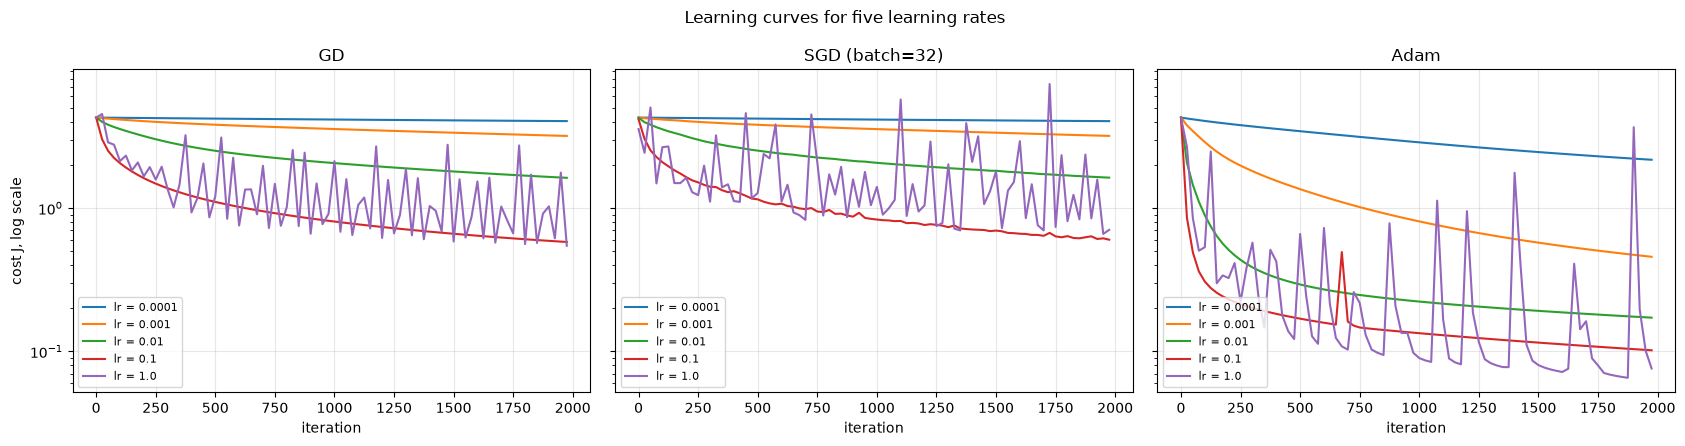

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for j, name in enumerate(OPTIMIZERS):
    for lr in LEARNING_RATES:
        ax[j].plot(iters, lr_results[(name, lr)]["costs"], label=f"lr = {lr}")
    ax[j].set_yscale("log")
    ax[j].set_xlabel("iteration")
    ax[j].set_title(name)
    ax[j].grid(alpha=0.3)
    ax[j].legend(fontsize=8)
ax[0].set_ylabel("cost J, log scale")
plt.suptitle("Learning curves for five learning rates")
plt.tight_layout()
plt.show()

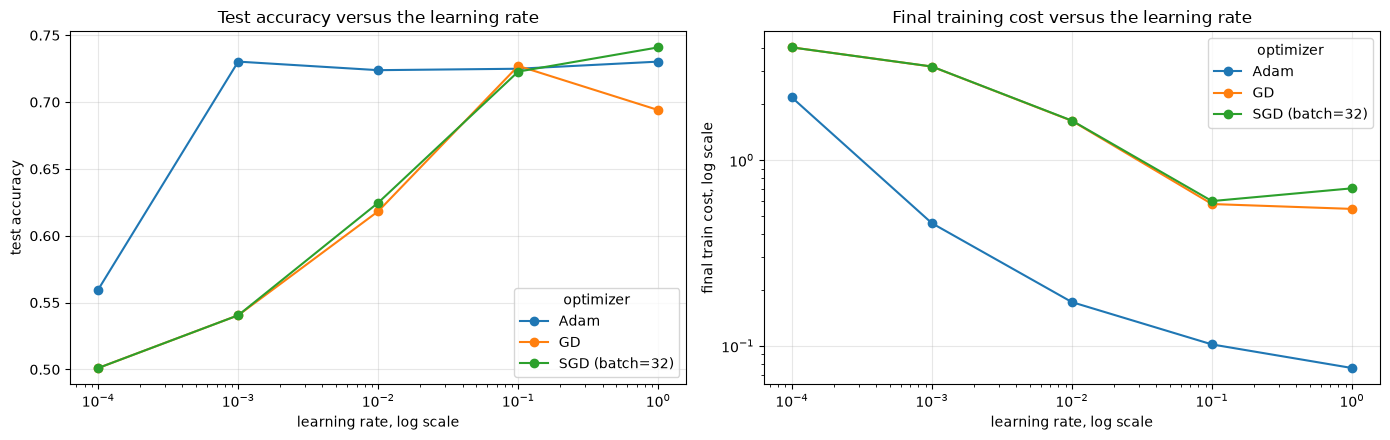

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pivot_test.plot(marker="o", ax=ax[0])
ax[0].set_xscale("log")
ax[0].set_xlabel("learning rate, log scale")
ax[0].set_ylabel("test accuracy")
ax[0].set_title("Test accuracy versus the learning rate")
ax[0].grid(alpha=0.3)

pivot_cost.plot(marker="o", ax=ax[1])
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("learning rate, log scale")
ax[1].set_ylabel("final train cost, log scale")
ax[1].set_title("Final training cost versus the learning rate")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**How the learning rate affects the model.** The learning rate turns out to be the single most important
hyperparameter here — it changes the accuracy far more than the choice of the optimizer does.

- **Too small** ($10^{-4}$, $10^{-3}$): the step is so short that after 2000 iterations the model is still
  near its random initialization. The cost is barely reduced and the accuracy stays at the level of random
  guessing — at $10^{-4}$ it is even below the majority-class baseline of 54%, because the predictions still
  come from the random initial weights. The model is not undertrained in the statistical sense, it simply has
  not had time to travel to the minimum.
- **Reasonable** ($10^{-2}$ … $10^{-1}$ for GD and SGD): the cost falls steadily and the accuracy reaches its
  useful level. This is the region one should look for in practice.
- **Too large** (1.0 for GD): the step overshoots the minimum and the learning curve stops falling smoothly.
  Interestingly the *final training cost* is still marginally lower than at $\alpha = 0.1$, so looking at the
  loss alone would hide the problem. The test accuracy shows it clearly: it drops by about three percentage
  points, because the oscillating trajectory never settles in the minimum and ends wherever the last large
  step happened to throw it.

The three methods differ in how sensitive they are, and the exact numbers are in the table above:

- **GD** has the narrowest sweet spot: it is the only method whose test accuracy degrades on both sides of it;
- **SGD** tolerates larger rates than GD here, because each step is taken on a noisy mini-batch gradient and
  the effective displacement is averaged over many cheap iterations;
- **Adam** is by far the most robust — it reaches a low training cost across three orders of magnitude of
  the learning rate ($10^{-3}$ … $1$), and its test accuracy varies by less than one percentage point over
  that whole range, while GD swings by almost twenty. This is
  exactly the point of the adaptive step: dividing by $\sqrt{\hat{s}}$ normalizes the gradient magnitude, so
  the same $\alpha$ works over orders of magnitude of gradient scale. The flip side is visible in the table:
  the lowest training cost does not translate into the best test accuracy.

## 6. Conclusions

1. **A logistic regression written as a one-neuron neural network solves the task.** With backpropagation
   implemented by hand in numpy and a properly chosen learning rate, the model reaches a test accuracy
   noticeably above the majority-class baseline of 54%, using nothing but the four functions from the seminar
   notebook plus the three optimizers.

2. **SGD matches GD at a fraction of the computational cost.** Replacing the full-batch gradient with a
   mini-batch of 32 objects changes the quality very little at the same learning rate, while one iteration
   processes 88 times fewer objects and the whole training takes an order of magnitude less wall-clock time.
   With its own best learning rate SGD even gives the highest test accuracy of the three. This is the entire
   reason SGD is the default in deep learning: the gradient of a small batch is a noisy but unbiased estimate
   of the true gradient, and many cheap noisy steps beat few expensive exact ones.

3. **Adam minimizes the training loss far better than both — and that is not the same as a better model.**
   It reaches a training cost several times lower than GD and a training accuracy close to 1, yet its test
   accuracy ends up within a fraction of a percentage point of plain GD. The gap between training and test
   accuracy is the signature of overfitting:
   with 1776 free parameters and ~2800 training objects, an optimizer that is good at driving the loss down
   simply finds the overfitting solution faster. The fix belongs to the model, not to the optimizer —
   regularization ($L_1$ / $L_2$), early stopping or feature selection.

4. **The learning rate matters more than the choice of the optimizer.** Across four orders of magnitude it
   moves the test accuracy from the level of random guessing to the best result obtained in this work, whereas
   switching between GD, SGD and Adam at a fixed sensible rate changes it by a few percentage points. Too
   small a rate leaves the model untrained within the iteration budget, too large a one makes the cost
   oscillate and grow.

5. **Adaptivity buys robustness, not accuracy.** Adam's per-parameter step makes it work across a wide range
   of learning rates, which saves tuning effort — a real advantage on data like this, where a large part of
   the 1776 descriptors are binary and sparsely active, so the gradient scale differs wildly between features.
   On this particular task, however, the extra optimization power does not improve generalization.

6. **Practical recipe suggested by the experiments:** use mini-batch SGD or Adam rather than full-batch GD,
   spend the tuning effort on the learning rate first, and judge the result by the test metric rather than by
   how low the training curve goes.